In [1]:
pip install xlrd xgboost lightgbm catboost -q

Note: you may need to restart the kernel to use updated packages.


In [2]:
import json
import time
import warnings
from os import getenv
from pathlib import Path

import mlflow
import mlflow.sklearn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from mlflow.tracking import MlflowClient
from scipy.stats import randint, uniform, loguniform

from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    log_loss,
    make_scorer,
    classification_report,
    ConfusionMatrixDisplay,
)
from sklearn.ensemble import HistGradientBoostingClassifier, ExtraTreesClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 160)

In [3]:
# Raw files (works with the files you uploaded here)
SCORES_PATH   = Path("../../data/processed/20190108_scores_and_weak_links.csv")
FEATURES_PATH = Path("../../data/processed/AimoScore_WeakLink_big_scores.csv")

# Fallback to your project-style processed paths if the raw files are not in the notebook folder

def load_table(path: Path) -> pd.DataFrame:
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    return pd.read_excel(path)


scores = load_table(SCORES_PATH)
big = load_table(FEATURES_PATH)

print("scores:", scores.shape, "|", SCORES_PATH)
print("big:", big.shape, "|", FEATURES_PATH)

display(scores.head(2))
display(big.head(2))

scores: (2096, 17) | ..\..\data\processed\20190108_scores_and_weak_links.csv
big: (2094, 43) | ..\..\data\processed\AimoScore_WeakLink_big_scores.csv


,ID,Date,SCORE,ForwardHead,LeftArmFallForward,RightArmFallForward,LeftShoulderElevation,RightShoulderElevation,ExcessiveForwardLean,LeftAsymmetricalWeightShift,RightAsymmetricalWeightShift,LeftKneeMovesInward,RightKneeMovesInward,LeftKneeMovesOutward,RightKneeMovesOutward,LeftHeelRises,RightHeelRises
0,cf0e95ab-d6ec-475a-9cc0-c9444b8dd080.Kinect,2018-07-19,0.612532,0.31,1.34,1.15,0.33,0.49,0.00,0.0,0.08,0.0,0.0,0.0,0.77,0.0,0.0
1,6210cc6d-575d-4e9f-bab1-4fe1da2a30a3.Kinect,2018-07-30,0.388809,1.49,1.42,1.39,0.00,0.00,1.08,0.1,0.00,0.0,0.0,0.0,0.40,0.0,0.0


,AimoScore,No_1_Angle_Deviation,No_2_Angle_Deviation,No_3_Angle_Deviation,No_4_Angle_Deviation,No_5_Angle_Deviation,No_6_Angle_Deviation,No_7_Angle_Deviation,No_8_Angle_Deviation,No_9_Angle_Deviation,No_10_Angle_Deviation,No_11_Angle_Deviation,No_12_Angle_Deviation,No_13_Angle_Deviation,No_1_NASM_Deviation,No_2_NASM_Deviation,No_3_NASM_Deviation,No_4_NASM_Deviation,No_5_NASM_Deviation,No_6_NASM_Deviation,No_7_NASM_Deviation,No_8_NASM_Deviation,No_9_NASM_Deviation,No_10_NASM_Deviation,No_11_NASM_Deviation,No_12_NASM_Deviation,No_13_NASM_Deviation,No_14_NASM_Deviation,No_15_NASM_Deviation,No_16_NASM_Deviation,No_17_NASM_Deviation,No_18_NASM_Deviation,No_19_NASM_Deviation,No_20_NASM_Deviation,No_21_NASM_Deviation,No_22_NASM_Deviation,No_23_NASM_Deviation,No_24_NASM_Deviation,No_25_NASM_Deviation,No_1_Time_Deviation,No_2_Time_Deviation,EstimatedScore,ID
0,0.323667,0.538020,0.815878,0.346724,0.382114,0.302248,0.947872,0.275945,0.52176,0.457198,0.210426,0.835007,0.451937,0.178862,0.302248,0.275945,0.538020,0.210426,0.178862,0.778575,0.214730,0.428503,0.300813,0.432329,0.730751,0.606408,0.829747,0.838833,0.459110,0.652798,0.711143,0.587757,0.833094,0.656624,0.642276,0.552846,0.648972,0.578192,0.560019,0.821616,0.818747,0.209947,0003cdcc-86ed-494a-a3b5-90d09e96e06b.Kinect
1,0.323699,0.443807,0.306552,0.823529,0.188905,0.497370,0.140124,0.664275,0.52176,0.729316,0.912482,0.635581,0.222382,0.765184,0.497370,0.664275,0.443807,0.912482,0.765184,0.493544,0.164993,0.370636,0.361071,0.835007,0.983262,0.733620,0.625060,0.727881,0.841703,0.619321,0.378288,0.441416,0.670971,0.721186,0.826399,0.805356,0.848876,0.889048,0.816834,0.307987,0.248207,0.457198,003115c4-bdb8-491c-b571-8fcebdecf8ed.Kinect


In [4]:
# Adjust if your env is elsewhere
load_dotenv("../../../../../env")

tracking_uri = getenv("MLFLOW_TRACKING_URI")
print("MLFLOW_TRACKING_URI =", tracking_uri)

if tracking_uri:
    mlflow.set_tracking_uri(tracking_uri)
else:
    raise RuntimeError("MLFLOW_TRACKING_URI not set. Fix env path/variable.")

EXPERIMENT_NAME = "A6_Classification_WeightedF1_Max"
mlflow.set_experiment(EXPERIMENT_NAME)

client = MlflowClient()
print("Tracking:", mlflow.get_tracking_uri())
print("Experiment:", EXPERIMENT_NAME)

MLFLOW_ARTIFACT_DIR = Path("mlflow_artifacts")
MLFLOW_ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

MLFLOW_TRACKING_URI = https://172.27.62.170:5001/


2026/03/10 09:49:17 INFO mlflow.tracking.fluent: Experiment with name 'A6_Classification_WeightedF1_Max' does not exist. Creating a new experiment.


Tracking: https://172.27.62.170:5001/
Experiment: A6_Classification_WeightedF1_Max


In [5]:
RANDOM_SEED = 42
FAST_MODE = False  # set True while debugging

N_ITER_SMALL = 10 if FAST_MODE else 20
N_ITER_MEDIUM = 15 if FAST_MODE else 30
N_ITER_LARGE = 20 if FAST_MODE else 40

f1_weighted = make_scorer(f1_score, average="weighted", zero_division=0)
COMP_RESULTS = []


def get_model_classes(model):
    if hasattr(model, "classes_"):
        return list(model.classes_)
    if hasattr(model, "named_steps"):
        last = list(model.named_steps.values())[-1]
        if hasattr(last, "classes_"):
            return list(last.classes_)
    return None


def align_proba_to_classes(proba, model_classes, target_classes, eps=1e-12):
    model_classes = [str(c) for c in model_classes]
    target_classes = [str(c) for c in target_classes]

    idx_map = {c: i for i, c in enumerate(model_classes)}
    aligned = np.full((proba.shape[0], len(target_classes)), eps, dtype=float)

    for j, c in enumerate(target_classes):
        if c in idx_map:
            aligned[:, j] = proba[:, idx_map[c]]

    aligned = aligned / np.clip(aligned.sum(axis=1, keepdims=True), eps, None)
    return aligned


def classification_metrics(y_true, y_pred, proba=None, classes=None, proba_classes=None, model=None):
    out = {
        "accuracy": float(accuracy_score(y_true, y_pred)),
        "balanced_accuracy": float(balanced_accuracy_score(y_true, y_pred)),
        "macro_f1": float(f1_score(y_true, y_pred, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, average="weighted", zero_division=0)),
    }

    if proba is not None and classes is not None:
        model_classes = proba_classes if proba_classes is not None else get_model_classes(model)

        if model_classes is not None and list(map(str, model_classes)) != list(map(str, classes)):
            proba = align_proba_to_classes(proba, model_classes, classes)

        out["log_loss"] = float(log_loss(y_true, proba, labels=classes))

    return out


def _mlflow_safe(v):
    if isinstance(v, np.generic):
        return v.item()
    if isinstance(v, Path):
        return str(v)
    if isinstance(v, np.ndarray):
        return json.dumps(v.tolist(), default=str)
    if isinstance(v, (list, tuple, set, dict)):
        return json.dumps(v, default=str)
    if v is None:
        return "None"
    return v


def _stringify_params(d):
    return {str(k): _mlflow_safe(v) for k, v in d.items()}


def _save_run_artifacts(run_name, row):
    safe_name = run_name.replace("/", "_").replace(" ", "_")
    run_dir = MLFLOW_ARTIFACT_DIR / safe_name
    run_dir.mkdir(parents=True, exist_ok=True)

    report = classification_report(
        y_test,
        row["test_pred"],
        labels=ALL_CLASSES,
        output_dict=True,
        zero_division=0,
    )
    with open(run_dir / "classification_report.json", "w", encoding="utf-8") as f:
        json.dump(report, f, indent=2)

    pred_df = pd.DataFrame({
        "y_true": pd.Series(y_test).reset_index(drop=True),
        "y_pred": pd.Series(row["test_pred"]).reset_index(drop=True),
    })
    pred_df.to_csv(run_dir / "test_predictions.csv", index=False)

    if row["test_proba"] is not None:
        proba_df = pd.DataFrame(
            np.asarray(row["test_proba"]),
            columns=[f"proba_{c}" for c in ALL_CLASSES],
        )
        proba_df.to_csv(run_dir / "test_probabilities.csv", index=False)

    with open(run_dir / "best_params.json", "w", encoding="utf-8") as f:
        json.dump(row["best_params"], f, indent=2, default=str)

    fig, ax = plt.subplots(figsize=(10, 8))
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        row["test_pred"],
        labels=ALL_CLASSES,
        xticks_rotation=90,
        ax=ax,
    )
    plt.tight_layout()
    fig.savefig(run_dir / "confusion_matrix.png", dpi=160, bbox_inches="tight")
    plt.close(fig)

    return run_dir


def log_run_to_mlflow(run_name, row, search=None, extra_params=None):
    extra_params = extra_params or {}

    with mlflow.start_run(run_name=run_name):
        mlflow.set_tags({
            "objective_metric": "weighted_f1",
            "cv_scheme": "StratifiedKFold",
            "cv_folds": "5",
            "experiment_group": "classification_maximize_weighted_f1",
            "model_family": run_name,
        })

        base_params = {
            "random_seed": RANDOM_SEED,
            "fast_mode": FAST_MODE,
            "scoring": "weighted_f1",
            "n_train_rows": X_train.shape[0],
            "n_test_rows": X_test.shape[0],
            "n_features": X_train.shape[1],
            "n_classes": len(ALL_CLASSES),
            "scores_path": str(SCORES_PATH),
            "features_path": str(FEATURES_PATH),
        }

        if search is not None:
            base_params["search_type"] = type(search).__name__
            base_params["n_iter"] = getattr(search, "n_iter", None)

        mlflow.log_params(_stringify_params(base_params))
        mlflow.log_params(_stringify_params(extra_params))

        if search is not None:
            mlflow.log_params({
                f"best__{k}": _mlflow_safe(v)
                for k, v in search.best_params_.items()
            })

        mlflow.log_metrics({
            "cv_weighted_f1": float(row["cv_weighted_f1"]),
            "test_weighted_f1": float(row["test_weighted_f1"]),
            "accuracy": float(row["accuracy"]),
            "balanced_accuracy": float(row["balanced_accuracy"]),
            "macro_f1": float(row["macro_f1"]),
            "log_loss": float(row["log_loss"]) if pd.notna(row["log_loss"]) else np.nan,
            "seconds": float(row["seconds"]),
        })

        run_dir = _save_run_artifacts(run_name, row)
        mlflow.log_artifacts(str(run_dir), artifact_path="artifacts")

        if row.get("best_estimator") is not None:
            try:
                mlflow.sklearn.log_model(
                    sk_model=row["best_estimator"],
                    artifact_path="model",
                )
            except Exception as e:
                mlflow.log_text(str(e), "model_logging_error.txt")


def tune_and_eval(name, estimator, param_dist, n_iter, y_fit=None, decode_fn=None, proba_classes=None):
    search = RandomizedSearchCV(
        estimator=estimator,
        param_distributions=param_dist,
        n_iter=n_iter,
        scoring=f1_weighted,
        cv=cv,
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbose=1,
        refit=True,
        error_score=0.0,
        return_train_score=False,
    )

    t0 = time.perf_counter()
    search.fit(X_train, y_train if y_fit is None else y_fit)
    seconds = time.perf_counter() - t0

    best_est = search.best_estimator_

    raw_pred = best_est.predict(X_test)
    pred = decode_fn(raw_pred) if decode_fn is not None else np.asarray(raw_pred).ravel()

    proba = best_est.predict_proba(X_test) if hasattr(best_est, "predict_proba") else None
    row_proba_classes = None
    if proba is not None:
        row_proba_classes = list(proba_classes) if proba_classes is not None else get_model_classes(best_est)

    metrics = classification_metrics(
        y_test,
        pred,
        proba=proba,
        classes=ALL_CLASSES,
        proba_classes=row_proba_classes,
        model=best_est,
    )

    row = {
        "model": name,
        "cv_weighted_f1": float(search.best_score_),
        "test_weighted_f1": metrics["weighted_f1"],
        "accuracy": metrics["accuracy"],
        "balanced_accuracy": metrics["balanced_accuracy"],
        "macro_f1": metrics["macro_f1"],
        "log_loss": metrics.get("log_loss", np.nan),
        "seconds": seconds,
        "best_params": search.best_params_,
        "best_estimator": best_est,
        "test_pred": pred,
        "test_proba": proba,
        "proba_classes": row_proba_classes,
    }

    COMP_RESULTS.append(row)

    print(f"\n==== {name} ====")
    print("CV weighted_f1:", row["cv_weighted_f1"])
    print("TEST weighted_f1:", row["test_weighted_f1"])
    print("Seconds:", row["seconds"])
    print("Best params:", row["best_params"])

    log_run_to_mlflow(name, row, search=search)

    return best_est, row


def soft_vote_rows(name, rows, weights=None):
    if weights is None:
        weights = np.ones(len(rows), dtype=float)

    weights = np.asarray(weights, dtype=float)
    weights = weights / weights.sum()

    blended = np.zeros((len(X_test), len(ALL_CLASSES)), dtype=float)

    for w, row in zip(weights, rows):
        proba = np.asarray(row["test_proba"], dtype=float)
        proba_classes = row.get("proba_classes", None)

        if proba_classes is not None and list(map(str, proba_classes)) != list(map(str, ALL_CLASSES)):
            proba = align_proba_to_classes(proba, proba_classes, ALL_CLASSES)

        blended += w * proba

    pred = np.array(ALL_CLASSES)[np.argmax(blended, axis=1)]

    metrics = classification_metrics(
        y_test,
        pred,
        proba=blended,
        classes=ALL_CLASSES,
        proba_classes=ALL_CLASSES,
        model=None,
    )

    row = {
        "model": name,
        "cv_weighted_f1": float(np.average([r["cv_weighted_f1"] for r in rows], weights=weights)),
        "test_weighted_f1": metrics["weighted_f1"],
        "accuracy": metrics["accuracy"],
        "balanced_accuracy": metrics["balanced_accuracy"],
        "macro_f1": metrics["macro_f1"],
        "log_loss": metrics.get("log_loss", np.nan),
        "seconds": float(np.sum([r["seconds"] for r in rows])),
        "best_params": {r["model"]: r["best_params"] for r in rows},
        "best_estimator": None,
        "test_pred": pred,
        "test_proba": blended,
        "proba_classes": ALL_CLASSES,
    }

    COMP_RESULTS.append(row)

    print(f"\n==== {name} ====")
    print("CV weighted_f1 (weighted avg of members):", row["cv_weighted_f1"])
    print("TEST weighted_f1:", row["test_weighted_f1"])

    log_run_to_mlflow(
        name,
        row,
        search=None,
        extra_params={
            "ensemble_members": [r["model"] for r in rows],
            "ensemble_weights": weights.tolist(),
        },
    )

    return row

In [6]:
NON_INDICATORS = {"ID", "Date", "SCORE"}
DROP_WEAK_LINKS = {
    "LeftHeelRises",
    "RightHeelRises",
    "LeftKneeMovesInward",
    "RightKneeMovesInward",
    "RightAsymmetricalWeightShift",
}

indicator_cols = [c for c in scores.columns if c not in NON_INDICATORS]
indicator_cols = [c for c in indicator_cols if c not in DROP_WEAK_LINKS]

scores[indicator_cols] = scores[indicator_cols].apply(pd.to_numeric, errors="coerce")

row_max = scores[indicator_cols].max(axis=1)
scores["HasTie"] = (scores[indicator_cols].eq(row_max, axis=0).sum(axis=1) > 1)
scores["WeakestLink"] = scores[indicator_cols].idxmax(axis=1)

labels = scores[["ID", "WeakestLink", "HasTie"]].dropna().copy()
df = big.merge(labels, on="ID", how="inner")

print("Merged df:", df.shape)
print("Tie rows:", int(df["HasTie"].sum()))

df = df.loc[~df["HasTie"]].copy()

y = df["WeakestLink"].astype(str)
rare_classes = y.value_counts()[lambda s: s < 5].index.tolist()

if rare_classes:
    print("Dropping classes with <5 rows so 5-fold stratified CV is valid:", rare_classes)
    df = df.loc[~y.isin(rare_classes)].copy()
    y = df["WeakestLink"].astype(str)

X = df.drop(columns=["ID", "WeakestLink", "HasTie"], errors="ignore").apply(pd.to_numeric, errors="coerce")
ALL_CLASSES = sorted(y.unique())

print("Final X:", X.shape)
print("Classes:", len(ALL_CLASSES))
print("Min class count:", int(y.value_counts().min()))
display(y.value_counts())

Merged df: (2094, 45)
Tie rows: 367
Final X: (1727, 42)
Classes: 9
Min class count: 50


WeakestLink
RightArmFallForward            466
LeftArmFallForward             337
RightKneeMovesOutward          278
RightShoulderElevation         266
ExcessiveForwardLean           101
ForwardHead                     96
LeftAsymmetricalWeightShift     75
LeftShoulderElevation           58
LeftKneeMovesOutward            50
Name: count, dtype: int64

In [7]:
assert y.value_counts().min() >= 5, "Every class must have at least 5 rows for 5-fold stratified CV."

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_SEED,
    stratify=y,
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)

le = LabelEncoder()
le.fit(y_train)
y_train_enc = le.transform(y_train)

ALL_CLASSES = list(le.classes_)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Classes:", ALL_CLASSES)

X_train: (1381, 42)
X_test: (346, 42)
Classes: ['ExcessiveForwardLean', 'ForwardHead', 'LeftArmFallForward', 'LeftAsymmetricalWeightShift', 'LeftKneeMovesOutward', 'LeftShoulderElevation', 'RightArmFallForward', 'RightKneeMovesOutward', 'RightShoulderElevation']


In [8]:
hgb = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("hgb", HistGradientBoostingClassifier(random_state=RANDOM_SEED)),
])

param_hgb = {
    "hgb__learning_rate": loguniform(0.02, 0.20),
    "hgb__max_iter": randint(200, 801),
    "hgb__max_depth": [None, 3, 4, 5, 6, 8, 10],
    "hgb__max_leaf_nodes": randint(15, 256),
    "hgb__min_samples_leaf": randint(5, 61),
    "hgb__l2_regularization": loguniform(1e-3, 20.0),
    "hgb__early_stopping": [True],
    "hgb__validation_fraction": [0.1, 0.15, 0.2],
}

best_hgb, row_hgb = tune_and_eval(
    "HistGradientBoosting",
    hgb,
    param_hgb,
    n_iter=N_ITER_MEDIUM,
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

==== HistGradientBoosting ====
CV weighted_f1: 0.0
TEST weighted_f1: 0.6065342350967561
Seconds: 67.43764150002971
Best params: {'hgb__early_stopping': True, 'hgb__l2_regularization': np.float64(0.04082331665966554), 'hgb__learning_rate': np.float64(0.1785436060870726), 'hgb__max_depth': 4, 'hgb__max_iter': 271, 'hgb__max_leaf_nodes': 203, 'hgb__min_samples_leaf': 25, 'hgb__validation_fraction': 0.2}


2026/03/10 09:50:44 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run HistGradientBoosting at: https://172.27.62.170:5001/#/experiments/15/runs/251cd65d135144bda6917913692a4350
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/15


In [9]:
et = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("et", ExtraTreesClassifier(random_state=RANDOM_SEED, n_jobs=-1)),
])

param_et = {
    "et__n_estimators": [300, 500, 800, 1200],
    "et__max_depth": [None, 10, 20, 30, 40],
    "et__max_features": ["sqrt", 0.5, 0.8],
    "et__min_samples_split": randint(2, 12),
    "et__min_samples_leaf": randint(1, 5),
    "et__class_weight": [None, "balanced", "balanced_subsample"],
}

best_et, row_et = tune_and_eval(
    "ExtraTrees",
    et,
    param_et,
    n_iter=N_ITER_SMALL,
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

==== ExtraTrees ====
CV weighted_f1: 0.0
TEST weighted_f1: 0.6031180297890131
Seconds: 35.847752000030596
Best params: {'et__class_weight': 'balanced_subsample', 'et__max_depth': 30, 'et__max_features': 'sqrt', 'et__min_samples_leaf': 3, 'et__min_samples_split': 9, 'et__n_estimators': 300}


2026/03/10 10:00:14 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run ExtraTrees at: https://172.27.62.170:5001/#/experiments/15/runs/ee5ed2bf229747de9b0dd2839e426553
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/15


In [10]:
lgbm = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("lgbm", LGBMClassifier(
        objective="multiclass",
        random_state=RANDOM_SEED,
        n_jobs=-1,
        force_col_wise=True,
        verbosity=-1,
    )),
])

param_lgbm = {
    "lgbm__n_estimators": [300, 500, 800, 1200],
    "lgbm__learning_rate": loguniform(0.02, 0.12),
    "lgbm__num_leaves": randint(15, 128),
    "lgbm__max_depth": [-1, 3, 4, 5, 6, 8, 10],
    "lgbm__min_child_samples": randint(5, 50),
    "lgbm__subsample": uniform(0.65, 0.30),
    "lgbm__subsample_freq": [1],
    "lgbm__colsample_bytree": uniform(0.65, 0.30),
    "lgbm__reg_alpha": loguniform(1e-4, 3.0),
    "lgbm__reg_lambda": loguniform(1e-3, 10.0),
    "lgbm__class_weight": [None, "balanced"],
}

best_lgbm, row_lgbm = tune_and_eval(
    "LightGBM",
    lgbm,
    param_lgbm,
    n_iter=N_ITER_MEDIUM,
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

==== LightGBM ====
CV weighted_f1: 0.0
TEST weighted_f1: 0.6709642956235536
Seconds: 300.89788259996567
Best params: {'lgbm__class_weight': None, 'lgbm__colsample_bytree': np.float64(0.8889628960580699), 'lgbm__learning_rate': np.float64(0.027782415797062296), 'lgbm__max_depth': 6, 'lgbm__min_child_samples': 25, 'lgbm__n_estimators': 800, 'lgbm__num_leaves': 97, 'lgbm__reg_alpha': np.float64(0.00028028497694964656), 'lgbm__reg_lambda': np.float64(0.068706142826133), 'lgbm__subsample': np.float64(0.7501125833417066), 'lgbm__subsample_freq': 1}


2026/03/10 10:10:19 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run LightGBM at: https://172.27.62.170:5001/#/experiments/15/runs/35a8a872990c46fdae3be6fa566506b9
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/15


In [11]:
cat = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("cat", CatBoostClassifier(
        loss_function="MultiClass",
        random_seed=RANDOM_SEED,
        verbose=False,
        allow_writing_files=False,
    )),
])

param_cat = {
    "cat__iterations": [300, 500, 800, 1200],
    "cat__depth": [4, 5, 6, 7, 8],
    "cat__learning_rate": loguniform(0.02, 0.12),
    "cat__l2_leaf_reg": loguniform(1.0, 12.0),
    "cat__random_strength": loguniform(1e-3, 5.0),
    "cat__bagging_temperature": uniform(0.0, 1.0),
    "cat__border_count": [64, 128, 254],
}

best_cat, row_cat = tune_and_eval(
    "CatBoost",
    cat,
    param_cat,
    n_iter=N_ITER_MEDIUM,
)

Fitting 5 folds for each of 30 candidates, totalling 150 fits

==== CatBoost ====
CV weighted_f1: 0.0
TEST weighted_f1: 0.6524337348085808
Seconds: 3342.912994500017
Best params: {'cat__bagging_temperature': np.float64(0.3745401188473625), 'cat__border_count': 64, 'cat__depth': 6, 'cat__iterations': 1200, 'cat__l2_leaf_reg': np.float64(4.426505507739147), 'cat__learning_rate': np.float64(0.026450634586450826), 'cat__random_strength': np.float64(0.003775887545682684)}


2026/03/10 11:09:00 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run CatBoost at: https://172.27.62.170:5001/#/experiments/15/runs/58b19534fbef4eaeb8f5a266c9e2c45a
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/15


In [12]:
xgb_tree = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="multi:softprob",
        num_class=len(le.classes_),
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbosity=0,
    )),
])

param_xgb_tree = {
    "xgb__n_estimators": [600, 900, 1200, 1600],
    "xgb__max_depth": [3, 4, 5, 6],
    "xgb__learning_rate": loguniform(0.02, 0.08),
    "xgb__subsample": uniform(0.65, 0.30),
    "xgb__colsample_bytree": uniform(0.75, 0.25),
    "xgb__min_child_weight": [1, 2, 3, 5, 7, 10],
    "xgb__gamma": [0.0, 0.1, 0.2, 0.3, 0.5, 1.0],
    "xgb__reg_alpha": loguniform(1e-4, 1.0),
    "xgb__reg_lambda": loguniform(1e-3, 5.0),
    "xgb__max_delta_step": [0, 1, 2],
    "xgb__grow_policy": ["depthwise", "lossguide"],
}

best_xgb, row_xgb = tune_and_eval(
    "XGBoost_gbtree",
    xgb_tree,
    param_xgb_tree,
    n_iter=N_ITER_LARGE,
    y_fit=y_train_enc,
    decode_fn=lambda p: le.inverse_transform(np.asarray(p).astype(int)),
    proba_classes=ALL_CLASSES,
)

Fitting 5 folds for each of 40 candidates, totalling 200 fits

==== XGBoost_gbtree ====
CV weighted_f1: 0.67150864672991
TEST weighted_f1: 0.6473387961567915
Seconds: 277.430914400029
Best params: {'xgb__colsample_bytree': np.float64(0.9693348383452453), 'xgb__gamma': 0.2, 'xgb__grow_policy': 'depthwise', 'xgb__learning_rate': np.float64(0.04993211760055707), 'xgb__max_delta_step': 1, 'xgb__max_depth': 6, 'xgb__min_child_weight': 1, 'xgb__n_estimators': 1600, 'xgb__reg_alpha': np.float64(0.013140210226207382), 'xgb__reg_lambda': np.float64(0.007845206319942895), 'xgb__subsample': np.float64(0.6779308303417698)}


2026/03/10 11:14:00 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run XGBoost_gbtree at: https://172.27.62.170:5001/#/experiments/15/runs/19b3303d55d94c07acc7c8f5b5ee691d
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/15


In [13]:
bp = row_xgb["best_params"].copy()

def around_float(x, factors, lo=None, hi=None):
    vals = [float(x) * f for f in factors]
    if lo is not None:
        vals = [max(lo, v) for v in vals]
    if hi is not None:
        vals = [min(hi, v) for v in vals]
    return sorted({float(v) for v in vals})

def around_int(x, deltas, lo=None, hi=None):
    vals = [int(round(float(x))) + d for d in deltas]
    if lo is not None:
        vals = [max(lo, v) for v in vals]
    if hi is not None:
        vals = [min(hi, v) for v in vals]
    return sorted({int(v) for v in vals})


xgb_refine = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("xgb", XGBClassifier(
        objective="multi:softprob",
        num_class=len(le.classes_),
        tree_method="hist",
        eval_metric="mlogloss",
        random_state=RANDOM_SEED,
        n_jobs=-1,
        verbosity=0,
    )),
])

param_xgb_refine = {
    "xgb__n_estimators": around_int(bp["xgb__n_estimators"], [-300, 0, 300], 300, 2500),
    "xgb__max_depth": around_int(bp["xgb__max_depth"], [-1, 0, 1], 3, 8),
    "xgb__learning_rate": around_float(bp["xgb__learning_rate"], [0.7, 1.0, 1.3], 0.01, 0.12),
    "xgb__subsample": around_float(bp["xgb__subsample"], [0.9, 1.0, 1.1], 0.60, 1.00),
    "xgb__colsample_bytree": around_float(bp["xgb__colsample_bytree"], [0.9, 1.0, 1.1], 0.60, 1.00),
    "xgb__min_child_weight": around_int(bp["xgb__min_child_weight"], [-2, 0, 2], 1, 12),
    "xgb__gamma": sorted({0.0, float(bp["xgb__gamma"]), round(float(bp["xgb__gamma"]) + 0.2, 4)}),
    "xgb__reg_alpha": around_float(bp["xgb__reg_alpha"], [0.5, 1.0, 2.0], 1e-5, 2.0),
    "xgb__reg_lambda": around_float(bp["xgb__reg_lambda"], [0.5, 1.0, 2.0], 1e-4, 10.0),
    "xgb__max_delta_step": sorted({
        max(0, int(bp.get("xgb__max_delta_step", 0)) - 1),
        int(bp.get("xgb__max_delta_step", 0)),
        int(bp.get("xgb__max_delta_step", 0)) + 1,
    }),
    "xgb__grow_policy": [bp.get("xgb__grow_policy", "depthwise")],
}

best_xgb_refine, row_xgb_refine = tune_and_eval(
    "XGBoost_refine",
    xgb_refine,
    param_xgb_refine,
    n_iter=N_ITER_SMALL,
    y_fit=y_train_enc,
    decode_fn=lambda p: le.inverse_transform(np.asarray(p).astype(int)),
    proba_classes=ALL_CLASSES,
)

Fitting 5 folds for each of 20 candidates, totalling 100 fits

==== XGBoost_refine ====
CV weighted_f1: 0.6686913771629203
TEST weighted_f1: 0.6592392327255335
Seconds: 203.63819650001824
Best params: {'xgb__subsample': 0.6779308303417698, 'xgb__reg_lambda': 0.003922603159971448, 'xgb__reg_alpha': 0.006570105113103691, 'xgb__n_estimators': 1600, 'xgb__min_child_weight': 3, 'xgb__max_depth': 7, 'xgb__max_delta_step': 0, 'xgb__learning_rate': 0.04993211760055707, 'xgb__grow_policy': 'depthwise', 'xgb__gamma': 0.2, 'xgb__colsample_bytree': 0.8724013545107208}


2026/03/10 11:17:40 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


🏃 View run XGBoost_refine at: https://172.27.62.170:5001/#/experiments/15/runs/e09f615f14684c629acc28420ecbd67a
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/15


In [14]:
lb = pd.DataFrame([
    {
        "model": r["model"],
        "cv_weighted_f1": r["cv_weighted_f1"],
        "test_weighted_f1": r["test_weighted_f1"],
        "accuracy": r["accuracy"],
        "balanced_accuracy": r["balanced_accuracy"],
        "macro_f1": r["macro_f1"],
        "log_loss": r["log_loss"],
        "seconds": r["seconds"],
        "best_params": r["best_params"],
    }
    for r in COMP_RESULTS
]).sort_values(["test_weighted_f1", "cv_weighted_f1"], ascending=False).reset_index(drop=True)

display(lb)
print("Best by TEST weighted_f1:", lb.iloc[0]["model"], lb.iloc[0]["test_weighted_f1"])

lb_cv = lb.sort_values(["cv_weighted_f1", "test_weighted_f1"], ascending=False).reset_index(drop=True)
print("Best by CV weighted_f1:", lb_cv.iloc[0]["model"], lb_cv.iloc[0]["cv_weighted_f1"])

,model,cv_weighted_f1,test_weighted_f1,accuracy,balanced_accuracy,macro_f1,log_loss,seconds,best_params
0,LightGBM,0.000000,0.670964,0.682081,0.621493,0.621378,1.142049,300.897883,"{'lgbm__class_weight': None, 'lgbm__colsample_..."
1,XGBoost_refine,0.668691,0.659239,0.676301,0.615738,0.602484,0.942360,203.638197,"{'xgb__subsample': 0.6779308303417698, 'xgb__r..."
2,CatBoost,0.000000,0.652434,0.667630,0.592225,0.605202,0.914733,3342.912995,{'cat__bagging_temperature': 0.374540118847362...
3,XGBoost_gbtree,0.671509,0.647339,0.661850,0.596828,0.589480,0.933230,277.430914,"{'xgb__colsample_bytree': 0.9693348383452453, ..."
4,HistGradientBoosting,0.000000,0.606534,0.615607,0.553833,0.566604,1.016156,67.437642,"{'hgb__early_stopping': True, 'hgb__l2_regular..."
5,ExtraTrees,0.000000,0.603118,0.615607,0.601609,0.550865,1.187942,35.847752,"{'et__class_weight': 'balanced_subsample', 'et..."


Best by TEST weighted_f1: LightGBM 0.6709642956235536
Best by CV weighted_f1: XGBoost_gbtree 0.67150864672991


In [15]:
ensemble_members = sorted(
    [r for r in COMP_RESULTS if r["test_proba"] is not None],
    key=lambda r: r["cv_weighted_f1"],
    reverse=True,
)[:3]

weights = np.array([r["cv_weighted_f1"] for r in ensemble_members], dtype=float)
weights = weights / weights.sum()

display(pd.DataFrame({
    "model": [r["model"] for r in ensemble_members],
    "cv_weighted_f1": [r["cv_weighted_f1"] for r in ensemble_members],
    "weight": weights,
}))

row_softvote = soft_vote_rows(
    "SoftVote_top3_byCV",
    ensemble_members,
    weights=weights,
)

,model,cv_weighted_f1,weight
0,XGBoost_gbtree,0.671509,0.501051
1,XGBoost_refine,0.668691,0.498949
2,HistGradientBoosting,0.000000,0.000000



==== SoftVote_top3_byCV ====
CV weighted_f1 (weighted avg of members): 0.6701029730744824
TEST weighted_f1: 0.6605381640944872
🏃 View run SoftVote_top3_byCV at: https://172.27.62.170:5001/#/experiments/15/runs/5335482107f149adab2c4e599be51ee3
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/15


In [16]:
lb = pd.DataFrame([
    {
        "model": r["model"],
        "cv_weighted_f1": r["cv_weighted_f1"],
        "test_weighted_f1": r["test_weighted_f1"],
        "accuracy": r["accuracy"],
        "balanced_accuracy": r["balanced_accuracy"],
        "macro_f1": r["macro_f1"],
        "log_loss": r["log_loss"],
        "seconds": r["seconds"],
        "best_params": r["best_params"],
    }
    for r in COMP_RESULTS
]).sort_values(["test_weighted_f1", "cv_weighted_f1"], ascending=False).reset_index(drop=True)

display(lb)

best_row = max(COMP_RESULTS, key=lambda r: (r["test_weighted_f1"], r["cv_weighted_f1"]))
print("FINAL WINNER:", best_row["model"])
print("FINAL TEST weighted_f1:", best_row["test_weighted_f1"])

,model,cv_weighted_f1,test_weighted_f1,accuracy,balanced_accuracy,macro_f1,log_loss,seconds,best_params
0,LightGBM,0.000000,0.670964,0.682081,0.621493,0.621378,1.142049,300.897883,"{'lgbm__class_weight': None, 'lgbm__colsample_..."
1,SoftVote_top3_byCV,0.670103,0.660538,0.676301,0.617541,0.608938,0.927422,548.506752,{'XGBoost_gbtree': {'xgb__colsample_bytree': 0...
2,XGBoost_refine,0.668691,0.659239,0.676301,0.615738,0.602484,0.942360,203.638197,"{'xgb__subsample': 0.6779308303417698, 'xgb__r..."
3,CatBoost,0.000000,0.652434,0.667630,0.592225,0.605202,0.914733,3342.912995,{'cat__bagging_temperature': 0.374540118847362...
4,XGBoost_gbtree,0.671509,0.647339,0.661850,0.596828,0.589480,0.933230,277.430914,"{'xgb__colsample_bytree': 0.9693348383452453, ..."
5,HistGradientBoosting,0.000000,0.606534,0.615607,0.553833,0.566604,1.016156,67.437642,"{'hgb__early_stopping': True, 'hgb__l2_regular..."
6,ExtraTrees,0.000000,0.603118,0.615607,0.601609,0.550865,1.187942,35.847752,"{'et__class_weight': 'balanced_subsample', 'et..."


FINAL WINNER: LightGBM
FINAL TEST weighted_f1: 0.6709642956235536


LightGBM

                             precision    recall  f1-score   support

       ExcessiveForwardLean       0.67      0.80      0.73        20
                ForwardHead       0.76      0.68      0.72        19
         LeftArmFallForward       0.51      0.51      0.51        68
LeftAsymmetricalWeightShift       0.71      0.67      0.69        15
       LeftKneeMovesOutward       0.75      0.60      0.67        10
      LeftShoulderElevation       0.00      0.00      0.00        12
        RightArmFallForward       0.69      0.74      0.72        93
      RightKneeMovesOutward       0.96      0.98      0.97        56
     RightShoulderElevation       0.57      0.60      0.59        53

                   accuracy                           0.68       346
                  macro avg       0.63      0.62      0.62       346
               weighted avg       0.66      0.68      0.67       346



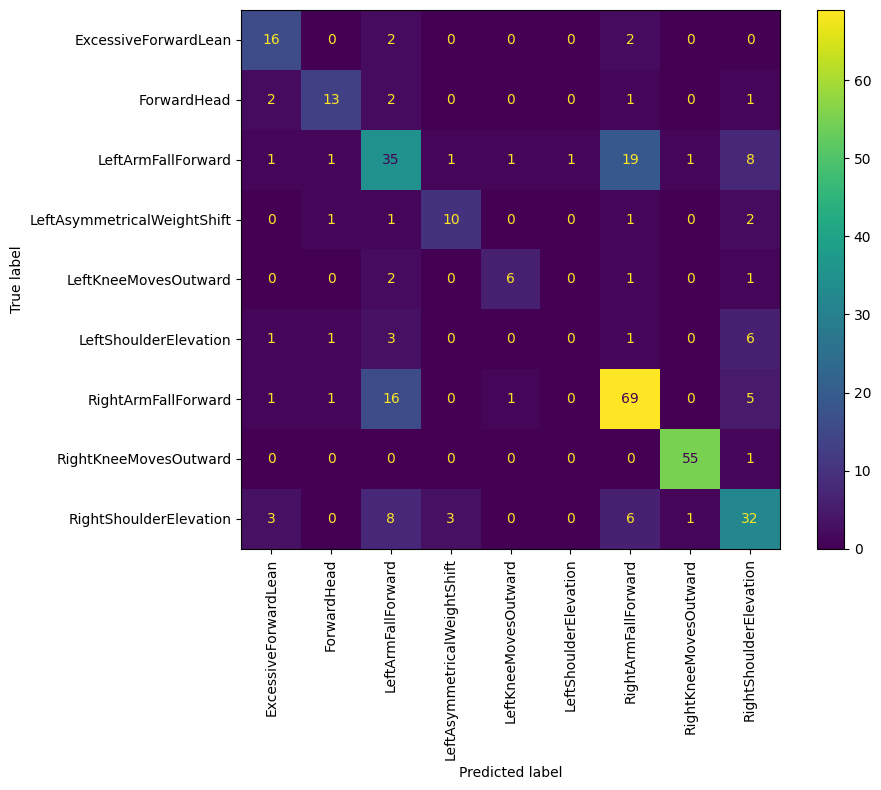

In [17]:
best_row = max(COMP_RESULTS, key=lambda r: (r["test_weighted_f1"], r["cv_weighted_f1"]))

print(best_row["model"])
print()
print(classification_report(y_test, best_row["test_pred"], zero_division=0))

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_row["test_pred"],
    xticks_rotation=90,
    ax=ax,
)
plt.tight_layout()
plt.show()

In [18]:
summary_lb = lb.copy()
summary_lb["best_params"] = summary_lb["best_params"].apply(lambda x: json.dumps(x, default=str))
summary_path = Path("weighted_f1_leaderboard.csv")
summary_lb.to_csv(summary_path, index=False)

best_row = max(COMP_RESULTS, key=lambda r: (r["test_weighted_f1"], r["cv_weighted_f1"]))

with mlflow.start_run(run_name="SUMMARY_final_leaderboard"):
    mlflow.set_tags({
        "objective_metric": "weighted_f1",
        "cv_folds": "5",
        "summary_run": "true",
    })
    mlflow.log_params({
        "winner_model": best_row["model"],
        "experiment_name": EXPERIMENT_NAME,
        "scores_path": str(SCORES_PATH),
        "features_path": str(FEATURES_PATH),
    })
    mlflow.log_metrics({
        "winner_test_weighted_f1": float(best_row["test_weighted_f1"]),
        "winner_cv_weighted_f1": float(best_row["cv_weighted_f1"]),
        "winner_accuracy": float(best_row["accuracy"]),
        "winner_balanced_accuracy": float(best_row["balanced_accuracy"]),
        "winner_macro_f1": float(best_row["macro_f1"]),
        "winner_log_loss": float(best_row["log_loss"]) if pd.notna(best_row["log_loss"]) else np.nan,
    })
    mlflow.log_artifact(str(summary_path))
    mlflow.log_text(best_row["model"], "winner.txt")

print("MLflow logging done.")
print("Winner:", best_row["model"])
print("Winner TEST weighted_f1:", best_row["test_weighted_f1"])

🏃 View run SUMMARY_final_leaderboard at: https://172.27.62.170:5001/#/experiments/15/runs/c899e7ebe396453daed883700cc32909
🧪 View experiment at: https://172.27.62.170:5001/#/experiments/15
MLflow logging done.
Winner: LightGBM
Winner TEST weighted_f1: 0.6709642956235536
